# CHIRPS v2 daily rainfall EDA

Explore CHIRPS v2.0 Final daily precipitation over Kalimantan for **2020-01-01 through 2024-12-31**, the study period in Mahdiyasa et al. (2026). The paper identifies CHIRPS rainfall but does not pin the product version or its 5 km aggregation rule; we selected v2 Final for a documented reconstruction.

- [Climate Hazards Center CHIRPS v2](https://www.chc.ucsb.edu/data/chirps) and [Earth Engine CHIRPS daily collection](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY)
- Native resolution: 0.05°; daily precipitation: **mm/day** ([Earth Engine catalog](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY))
- Local download: `data/interim/chirps_v2/`, produced by `scripts/download_chirps_v2.py --project kalimantan-peat` using the existing Earth Engine login. It is a spatial subset of the source grid; it has **not** been resampled to the paper's 5 × 5 km grid or clipped to peatland.

The notebook uses the five BIG province polygons only to summarize Kalimantan rainfall. Rainfall outside the province boundaries remains in the downloaded window for later alignment choices.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import shape
from shapely.plotting import plot_polygon


## 1. Load the five annual subsets and verify their grid

The compressed annual files contain `precipitation_mm_day` with shape `(day, latitude, longitude)`, UTC date labels, and pixel-center coordinates. Negative source no-data values were converted to `NaN` by the download script.


In [2]:
data_dir = Path("data/interim/chirps_v2")
manifest = json.loads((data_dir / "manifest.json").read_text())
annual = {}
for year in range(2020, 2025):
    with np.load(data_dir / f"chirps_v2_kalimantan_{year}.npz") as data:
        annual[year] = {
            "rain": data["precipitation_mm_day"],
            "dates": pd.to_datetime(data["dates"]),
        }
        if year == 2020:
            latitude = data["latitude"]
            longitude = data["longitude"]
        else:
            assert np.array_equal(latitude, data["latitude"])
            assert np.array_equal(longitude, data["longitude"])

print("Source:", manifest["source"])
print("Grid:", len(latitude), "rows ×", len(longitude), "columns")
print("Native step:", round(abs(np.diff(latitude).mean()), 5), "degrees latitude ×",
      round(np.diff(longitude).mean(), 5), "degrees longitude")
print("Years:", {year: len(item["dates"]) for year, item in annual.items()})


Source: CHIRPS v2.0 Final daily, Climate Hazards Center, accessed via Google Earth Engine
Grid: 190 rows × 220 columns
Native step: 0.05 degrees latitude × 0.05 degrees longitude
Years: {2020: 366, 2021: 365, 2022: 365, 2023: 365, 2024: 366}


In [3]:
dates = pd.DatetimeIndex(np.concatenate([annual[y]["dates"].values for y in annual]))
expected = pd.date_range("2020-01-01", "2024-12-31", freq="D")
print(f"Days present: {len(dates):,} / {len(expected):,}")
print("Missing dates:", len(expected.difference(dates)))
print("Duplicate dates:", dates.duplicated().sum())
print("Chronological:", dates.is_monotonic_increasing)
assert dates.equals(expected), "Date coverage differs from the planned study period"


Days present: 1,827 / 1,827
Missing dates: 0
Duplicate dates: 0
Chronological: True


## 2. Define a province mask for descriptive summaries

This is **not** the peatland mask. It excludes surrounding ocean and neighboring countries when summarizing the rainfall distribution. Native pixels whose centers fall within a BIG provincial polygon are counted; boundary pixels may be handled differently in the final 5 km processing.


In [4]:
with Path("data/raw/boundaries/big_kalimantan_provinces.geojson").open(encoding="utf-8") as file:
    province_geojson = json.load(file)

def keep_xy(coordinates):
    if isinstance(coordinates[0], (int, float)):
        return coordinates[:2]
    return [keep_xy(part) for part in coordinates]

provinces = [(feature["properties"]["WADMPR"], shape({
    "type": feature["geometry"]["type"],
    "coordinates": keep_xy(feature["geometry"]["coordinates"]),
})) for feature in province_geojson["features"]]
province_union = shapely.union_all([geom for _, geom in provinces])
lon_grid, lat_grid = np.meshgrid(longitude, latitude)
province_mask = shapely.contains_xy(province_union, lon_grid, lat_grid)
print(f"Native grid cells with centers in the five provinces: {province_mask.sum():,}")


Native grid cells with centers in the five provinces: 17,382


## 3. Check missing values and rainfall range

A dry day has rainfall **0**, not missing. Ocean no-data values are expected in the rectangular download window; the key check is missingness inside the provinces.


In [5]:
quality_rows = []
daily_rows = []
annual_totals = []
for year, item in annual.items():
    rain = item["rain"]
    pixels = rain[:, province_mask]
    quality_rows.append({
        "year": year,
        "days": len(item["dates"]),
        "province_missing_pct": 100 * np.isnan(pixels).mean(),
        "province_all_missing_cells": int(np.isnan(pixels).all(axis=0).sum()),
        "province_zero_pct": 100 * np.mean(pixels == 0),
        "province_max_mm_day": np.nanmax(pixels),
        "province_mean_mm_day": np.nanmean(pixels),
    })
    daily_rows.append(pd.DataFrame({
        "date": item["dates"],
        "mean_mm_day": np.nanmean(pixels, axis=1),
        "wet_pixel_pct": 100 * np.nanmean(pixels >= 1, axis=1),
    }))
    annual_total = np.nansum(rain, axis=0)
    annual_total[np.isnan(rain).all(axis=0)] = np.nan
    annual_totals.append(annual_total)
quality = pd.DataFrame(quality_rows).set_index("year")
daily = pd.concat(daily_rows, ignore_index=True).set_index("date")
quality.round(2)


,days,province_missing_pct,province_all_missing_cells,province_zero_pct,province_max_mm_day,province_mean_mm_day
year,,,,,,
2020,366,0.01,1,37.48,167.970001,9.43
2021,365,0.01,1,36.26,192.619995,9.91
2022,365,0.01,1,33.12,147.160004,10.51
2023,365,0.01,1,44.44,170.190002,8.49
2024,366,0.01,1,39.74,156.089996,9.36


## 4. Temporal patterns

The daily series below is the mean across native CHIRPS pixels whose centers are in Kalimantan. The monthly sum of those daily means is an average regional monthly rainfall total, not a sum across land area.

The quality table includes native cells missing every day. Those cells remain missing in the annual map rather than being interpreted as zero rainfall.


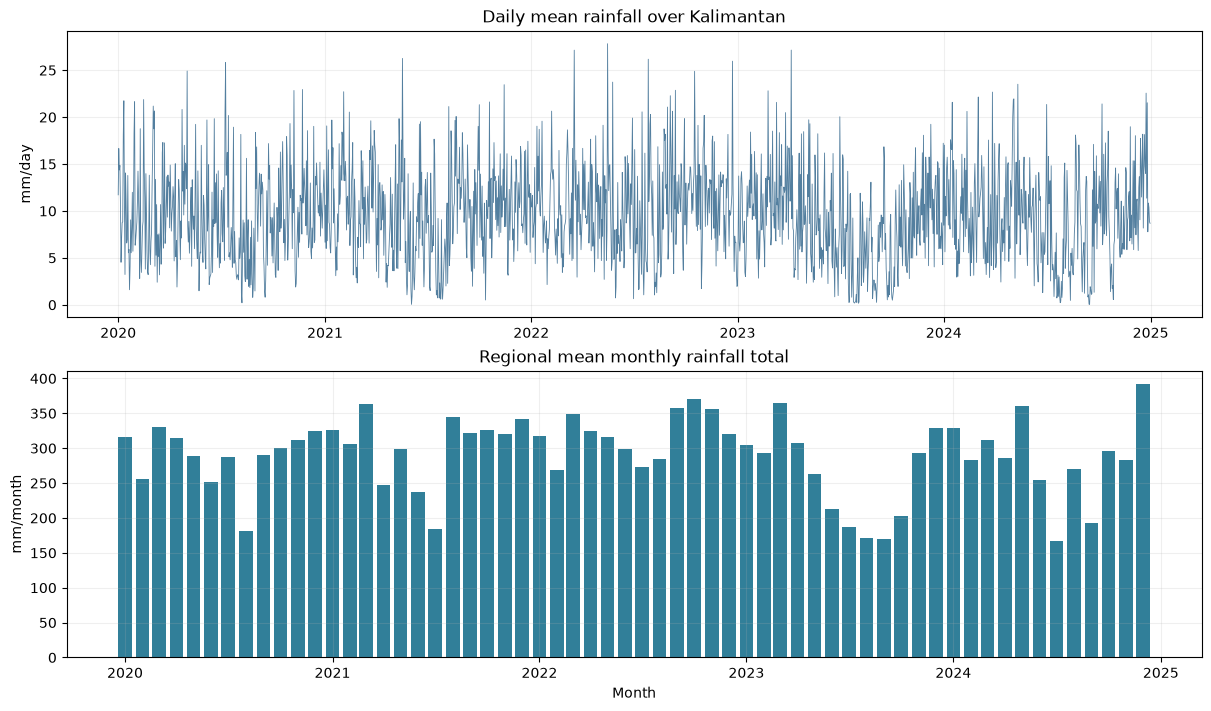

In [6]:
monthly = daily["mean_mm_day"].resample("MS").sum()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(daily.index, daily.mean_mm_day, color="#537f9f", linewidth=0.6)
axes[0].set(title="Daily mean rainfall over Kalimantan", ylabel="mm/day")
axes[1].bar(monthly.index, monthly.values, width=24, color="#317f99")
axes[1].set(title="Regional mean monthly rainfall total", ylabel="mm/month", xlabel="Month")
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()


In [7]:
month_profile = (monthly.groupby(monthly.index.month)
                 .agg(["mean", "min", "max"])
                 .rename_axis("month"))
month_profile.round(1)


,mean,min,max
month,,,
1,318.600006,304.799988,328.600006
2,281.299988,255.100006,305.899994
3,343.899994,311.100006,364.899994
4,295.799988,246.600006,325.000000
5,305.200012,262.500000,360.500000
6,251.199997,213.399994,298.399994
7,219.800003,167.199997,287.200012
8,250.600006,171.600006,344.700012
9,266.100006,169.600006,357.299988


## 5. Spatial rainfall pattern

This map is mean **annual total** across 2020–2024, calculated at the native 0.05° grid. The coastline and internal borders come from BIG. This display uses a province-center mask and simplified boundaries; it is not a resampled model input.


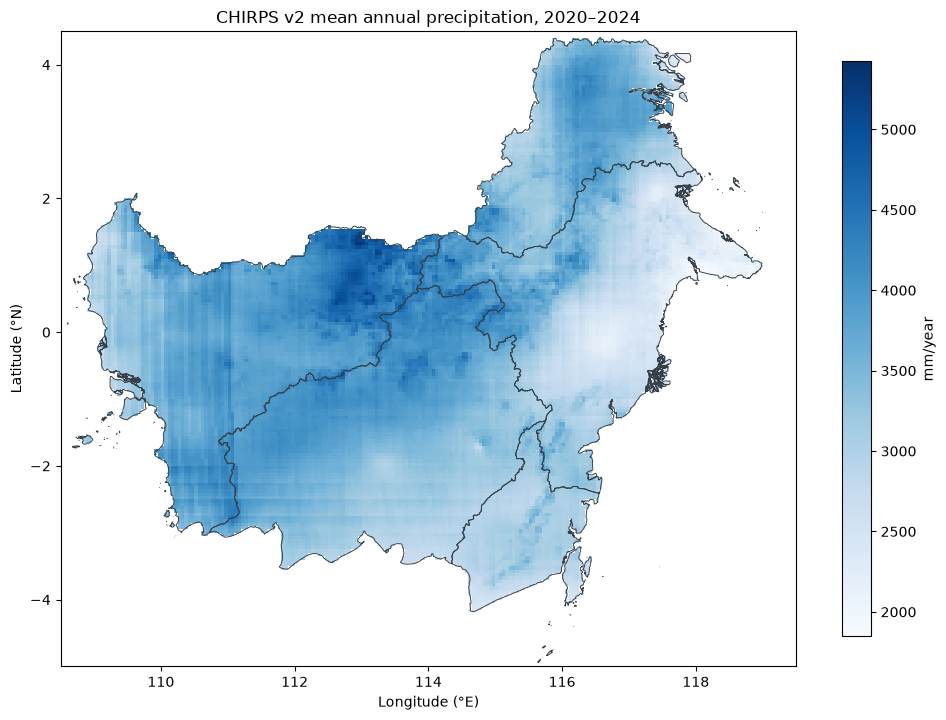

In [8]:
mean_annual_total = np.mean(annual_totals, axis=0)
image = np.ma.masked_where(~province_mask, mean_annual_total)
fig, ax = plt.subplots(figsize=(10, 8))
step_lon = np.diff(longitude).mean()
step_lat = abs(np.diff(latitude).mean())
im = ax.imshow(image, origin="upper", cmap="Blues", interpolation="nearest",
               extent=[longitude.min()-step_lon/2, longitude.max()+step_lon/2,
                       latitude.min()-step_lat/2, latitude.max()+step_lat/2])
for _, geom in provinces:
    plot_polygon(geom.simplify(0.003, preserve_topology=True), ax=ax,
                 add_points=False, facecolor="none", edgecolor="#354049", linewidth=0.7)
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)",
       title="CHIRPS v2 mean annual precipitation, 2020–2024")
ax.set_aspect("equal", adjustable="box")
fig.colorbar(im, ax=ax, shrink=0.75, label="mm/year")
plt.tight_layout(); plt.show()


## Interpretation before preprocessing

- Keep the `0.05°` CHIRPS grid and `mm/day` units recorded in the data manifest.
- Decide later how to aggregate rainfall onto our **project-defined 5 × 5 km grid**. The paper does not specify its exact spatial aggregation rule.
- Before modeling, choose the predictor's timing so rainfall measured on the target fire day cannot leak into a forecast made before that day.
- The plots describe all five provinces. The eventual model will use only the selected peatland study cells.
